In [1]:
import os
import random
import time
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score


def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(42)
print("Environment initialized with deterministic seed 42.")


Environment initialized with deterministic seed 42.


In [2]:
CORA_CLASSES = {
    0: "Case_Based",
    1: "Genetic_Algorithms",
    2: "Neural_Networks",
    3: "Probabilistic_Methods",
    4: "Reinforcement_Learning",
    5: "Rule_Learning",
    6: "Theory",
}


def load_cora():
    cache_path = "./data/cora/cora_cache.pt"
    if os.path.exists(cache_path):
        print(f"Loading Cora from disk cache: {cache_path}")
        return torch.load(cache_path, weights_only=False)

    try:
        from torch_geometric.datasets import Planetoid
    except ImportError:
        import subprocess
        import sys
        print("torch_geometric not found in this environment. Installing now for Colab...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "torch_geometric"])
        from torch_geometric.datasets import Planetoid

    print("Downloading and loading Cora dataset via PyTorch Geometric...")
    dataset = Planetoid(root="./data/Cora", name="Cora")
    data_obj = dataset[0]

    data = {
        "x": data_obj.x,
        "edge_index": data_obj.edge_index,
        "y": data_obj.y,
        "train_mask": data_obj.train_mask,
        "val_mask": data_obj.val_mask,
        "test_mask": data_obj.test_mask,
        "num_nodes": data_obj.num_nodes,
        "num_edges": data_obj.edge_index.size(1),
        "num_features": dataset.num_features,
        "num_classes": dataset.num_classes,
        "class_names": CORA_CLASSES,
    }
    os.makedirs(os.path.dirname(cache_path), exist_ok=True)
    torch.save(data, cache_path)
    return data


data = load_cora()
num_nodes = data["num_nodes"]
x = data["x"]
edge_index = data["edge_index"]
print(f"Cora loaded successfully: {num_nodes} nodes, {x.size(1)} features, {edge_index.size(1)} directed edges.")


torch_geometric not found in this environment. Installing now for Colab...


Processing...


Cora loaded successfully: 2708 nodes, 1433 features, 10556 directed edges.


Done!


In [3]:
# CELL 3: STRICT EDGE SPLITTER & DISJOINT NEGATIVE SAMPLER
# Extracts unique undirected edges (u < v) and splits into: 85% Train, 5% Val, 10% Test.
# Symmetrically places both (u, v) and (v, u) in the same split.
# Samples strictly disjoint negative edges for train, val, and test splits (no false negatives).


def split_edges_strictly(edge_index: torch.Tensor, num_nodes: int, train_ratio=0.85, val_ratio=0.05, seed=42):
    random.seed(seed)
    torch.manual_seed(seed)

    all_pos_set = set()
    for i in range(edge_index.size(1)):
        u, v = int(edge_index[0, i]), int(edge_index[1, i])
        if u != v:
            all_pos_set.add((min(u, v), max(u, v)))

    unique_edges = list(all_pos_set)
    random.shuffle(unique_edges)

    n_total = len(unique_edges)
    n_train = int(n_total * train_ratio)
    n_val = int(n_total * val_ratio)

    train_unique = unique_edges[:n_train]
    val_unique = unique_edges[n_train : n_train + n_val]
    test_unique = unique_edges[n_train + n_val :]

    def to_bidirectional(edge_list):
        src, dst = [], []
        for u, v in edge_list:
            src.extend([u, v])
            dst.extend([v, u])
        return torch.tensor([src, dst], dtype=torch.long)

    train_pos_edge_index = to_bidirectional(train_unique)
    val_pos = torch.tensor(val_unique, dtype=torch.long)
    test_pos = torch.tensor(test_unique, dtype=torch.long)

    val_neg_set = set()
    while len(val_neg_set) < len(val_unique):
        u = random.randint(0, num_nodes - 1)
        v = random.randint(0, num_nodes - 1)
        if u != v:
            pair = (min(u, v), max(u, v))
            if pair not in all_pos_set and pair not in val_neg_set:
                val_neg_set.add(pair)

    test_neg_set = set()
    while len(test_neg_set) < len(test_unique):
        u = random.randint(0, num_nodes - 1)
        v = random.randint(0, num_nodes - 1)
        if u != v:
            pair = (min(u, v), max(u, v))
            if pair not in all_pos_set and pair not in val_neg_set and pair not in test_neg_set:
                test_neg_set.add(pair)

    train_neg_set = set()
    while len(train_neg_set) < len(train_unique):
        u = random.randint(0, num_nodes - 1)
        v = random.randint(0, num_nodes - 1)
        if u != v:
            pair = (min(u, v), max(u, v))
            if pair not in all_pos_set and pair not in val_neg_set and pair not in test_neg_set and pair not in train_neg_set:
                train_neg_set.add(pair)

    return {
        "train_mp_edges": train_pos_edge_index,
        "train_pos": torch.tensor(train_unique, dtype=torch.long),
        "train_neg": torch.tensor(list(train_neg_set), dtype=torch.long),
        "val_pos": val_pos,
        "val_neg": torch.tensor(list(val_neg_set), dtype=torch.long),
        "test_pos": test_pos,
        "test_neg": torch.tensor(list(test_neg_set), dtype=torch.long),
        "all_pos_set": all_pos_set,
    }


splits = split_edges_strictly(edge_index, num_nodes, train_ratio=0.85, val_ratio=0.05, seed=42)
print("Edge splits created:")
print(f"  Train Positive Edges: {len(splits['train_pos'])} (MP Graph: {splits['train_mp_edges'].size(1)} directed edges)")
print(f"  Val Positive Edges:   {len(splits['val_pos'])} | Val Negative Edges:   {len(splits['val_neg'])}")
print(f"  Test Positive Edges:  {len(splits['test_pos'])} | Test Negative Edges:  {len(splits['test_neg'])}")



Edge splits created:
  Train Positive Edges: 4486 (MP Graph: 8972 directed edges)
  Val Positive Edges:   263 | Val Negative Edges:   263
  Test Positive Edges:  529 | Test Negative Edges:  529


In [4]:
# CELL 4: AUTOMATED DATA LEAKAGE VERIFICATION CHECK
# Proves mathematically that all held-out validation and test edges (and reverse copies)
# are strictly absent from the training message-passing graph (E_heldout intersect E_mp = empty set).


def assert_zero_data_leakage(train_mp_edges: torch.Tensor, val_pos: torch.Tensor, test_pos: torch.Tensor):
    mp_set = set()
    for i in range(train_mp_edges.size(1)):
        u, v = train_mp_edges[0, i].item(), train_mp_edges[1, i].item()
        mp_set.add((u, v))

    for i in range(len(val_pos)):
        u, v = val_pos[i, 0].item(), val_pos[i, 1].item()
        assert (u, v) not in mp_set, f"LEAKAGE: Val edge ({u}, {v}) found in message passing graph!"
        assert (v, u) not in mp_set, f"LEAKAGE: Reverse val edge ({v}, {u}) found in message passing graph!"

    for i in range(len(test_pos)):
        u, v = test_pos[i, 0].item(), test_pos[i, 1].item()
        assert (u, v) not in mp_set, f"LEAKAGE: Test edge ({u}, {v}) found in message passing graph!"
        assert (v, u) not in mp_set, f"LEAKAGE: Reverse test edge ({v}, {u}) found in message passing graph!"

    print("[PASS] Zero Data Leakage Confirmed:")
    print("       Held-out val and test edges are 100% absent from the message passing graph.")


assert_zero_data_leakage(splits["train_mp_edges"], splits["val_pos"], splits["test_pos"])


[PASS] Zero Data Leakage Confirmed:
       Held-out val and test edges are 100% absent from the message passing graph.


In [5]:
# CELL 5: GNN ENCODER & DECODERS (DOT-PRODUCT & SYMMETRIC MLP)
# GNNEncoder: 2-layer GraphSAGE generating latent node embeddings Z.
# DotProductDecoder: Score(u, v) = sigmoid(z_u^T * z_v).
# SymmetricMLPDecoder: Feed permutation-invariant features [|z_u - z_v| || z_u * z_v]
# guaranteeing Score(u, v) == Score(v, u) for undirected citation edges.


class GNNEncoder(nn.Module):
    def __init__(self, in_dim: int, hidden_dim: int, out_dim: int):
        super().__init__()
        self.lin_self1 = nn.Linear(in_dim, hidden_dim)
        self.lin_neigh1 = nn.Linear(in_dim, hidden_dim, bias=False)
        self.lin_self2 = nn.Linear(hidden_dim, out_dim)
        self.lin_neigh2 = nn.Linear(hidden_dim, out_dim, bias=False)

    def _mean_aggregate(self, x, edge_index):
        num_nodes = x.size(0)
        row, col = edge_index[0], edge_index[1]
        deg = torch.zeros(num_nodes, device=x.device)
        deg.index_add_(0, row, torch.ones(row.size(0), device=x.device))
        deg_clamp = deg.clamp(min=1.0).unsqueeze(-1)
        neigh_sum = torch.zeros(num_nodes, x.size(1), device=x.device)
        neigh_sum.index_add_(0, row, x[col])
        return neigh_sum / deg_clamp

    def forward(self, x, edge_index):
        neigh1 = self._mean_aggregate(x, edge_index)
        h1 = F.relu(self.lin_self1(x) + self.lin_neigh1(neigh1))
        neigh2 = self._mean_aggregate(h1, edge_index)
        z = self.lin_self2(h1) + self.lin_neigh2(neigh2)
        return z


class DotProductDecoder(nn.Module):
    def forward(self, z, edge_pairs):
        src, dst = edge_pairs[:, 0], edge_pairs[:, 1]
        scores = (z[src] * z[dst]).sum(dim=-1)
        return torch.sigmoid(scores)


class SymmetricMLPDecoder(nn.Module):
    def __init__(self, emb_dim: int, hidden_dim: int = 32):
        super().__init__()
        self.mlp = nn.Sequential(
            nn.Linear(2 * emb_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 1),
        )

    def forward(self, z, edge_pairs):
        src, dst = edge_pairs[:, 0], edge_pairs[:, 1]
        z_src = z[src]
        z_dst = z[dst]
        diff = torch.abs(z_src - z_dst)
        prod = z_src * z_dst
        pair_feat = torch.cat([diff, prod], dim=-1)
        scores = self.mlp(pair_feat).squeeze(-1)
        return torch.sigmoid(scores)


print("GNN Encoder and Decoders defined successfully.")

GNN Encoder and Decoders defined successfully.


In [6]:
# CELL 6: DECODER PAIR-REVERSAL INVARIANCE TEST
# Tests whether SymmetricMLPDecoder satisfies Score(u, v) == Score(v, u).
# Asserts maximum absolute discrepancy between forward and reversed pairs is < 1e-6.

dummy_z = torch.randn(num_nodes, 32)
mlp_dec_test = SymmetricMLPDecoder(emb_dim=32)
mlp_dec_test.eval()

test_pairs_fwd = torch.tensor([[10, 25], [100, 42], [500, 300]])
test_pairs_rev = torch.tensor([[25, 10], [42, 100], [300, 500]])

with torch.no_grad():
    score_fwd = mlp_dec_test(dummy_z, test_pairs_fwd)
    score_rev = mlp_dec_test(dummy_z, test_pairs_rev)

symmetry_diff = torch.max(torch.abs(score_fwd - score_rev)).item()
print(f"Forward pair scores:      {score_fwd.numpy()}")
print(f"Reversed pair scores:     {score_rev.numpy()}")
print(f"Max absolute discrepancy: {symmetry_diff:.8e}")
assert symmetry_diff < 1e-6, "Symmetric MLP decoder failed pair-reversal symmetry!"
print("[PASS] Pair-Reversal Symmetry Verified: Score(u, v) == Score(v, u) exactly.")


Forward pair scores:      [0.39319664 0.52935195 0.44740397]
Reversed pair scores:     [0.39319664 0.52935195 0.44740397]
Max absolute discrepancy: 0.00000000e+00
[PASS] Pair-Reversal Symmetry Verified: Score(u, v) == Score(v, u) exactly.


In [7]:
# CELL 7: COMMON NEIGHBORS HEURISTIC BASELINE
# Evaluates link prediction using raw graph topology: Score(u, v) = |N_train(u) cap N_train(v)|.
# Uses strictly the training graph edges to prevent data leakage.


def evaluate_common_neighbors(train_mp_edges: torch.Tensor, pos_pairs: torch.Tensor, neg_pairs: torch.Tensor, num_nodes: int):
    adj_set = [set() for _ in range(num_nodes)]
    for i in range(train_mp_edges.size(1)):
        u, v = train_mp_edges[0, i].item(), train_mp_edges[1, i].item()
        adj_set[u].add(v)

    def get_cn_scores(pairs):
        scores = []
        for i in range(len(pairs)):
            u, v = pairs[i, 0].item(), pairs[i, 1].item()
            scores.append(len(adj_set[u].intersection(adj_set[v])))
        return np.array(scores, dtype=np.float32)

    pos_scores = get_cn_scores(pos_pairs)
    neg_scores = get_cn_scores(neg_pairs)

    y_true = np.concatenate([np.ones_like(pos_scores), np.zeros_like(neg_scores)])
    y_scores = np.concatenate([pos_scores, neg_scores])

    auc = roc_auc_score(y_true, y_scores)
    ap = average_precision_score(y_true, y_scores)
    return auc, ap


cn_auc, cn_ap = evaluate_common_neighbors(splits["train_mp_edges"], splits["test_pos"], splits["test_neg"], num_nodes)
print(f"Common Neighbors Heuristic Baseline:")
print(f"  Test ROC-AUC:            {cn_auc:.4f}")
print(f"  Test Average Precision:  {cn_ap:.4f}")


Common Neighbors Heuristic Baseline:
  Test ROC-AUC:            0.7094
  Test Average Precision:  0.7077


In [8]:
# CELL 8: MODEL TRAINING & EVALUATION ENGINE
# Trains GNN encoder + decoder using Adam and Binary Cross-Entropy loss.
# Selects model checkpoints based on validation ROC-AUC.


def train_link_predictor(encoder, decoder, x, train_mp_edges, train_pos, train_neg, val_pos, val_neg, epochs=80, lr=0.01):
    optimizer = torch.optim.Adam(list(encoder.parameters()) + list(decoder.parameters()), lr=lr, weight_decay=1e-4)
    best_val_auc = 0.0
    best_weights = None

    for epoch in range(1, epochs + 1):
        encoder.train()
        decoder.train()
        optimizer.zero_grad()

        z = encoder(x, train_mp_edges)
        pos_scores = decoder(z, train_pos)
        neg_scores = decoder(z, train_neg)

        pos_loss = F.binary_cross_entropy(pos_scores, torch.ones_like(pos_scores))
        neg_loss = F.binary_cross_entropy(neg_scores, torch.zeros_like(neg_scores))
        loss = pos_loss + neg_loss

        loss.backward()
        optimizer.step()

        encoder.eval()
        decoder.eval()
        with torch.no_grad():
            z_val = encoder(x, train_mp_edges)
            val_pos_scores = decoder(z_val, val_pos).cpu().numpy()
            val_neg_scores = decoder(z_val, val_neg).cpu().numpy()
            y_true = np.concatenate([np.ones_like(val_pos_scores), np.zeros_like(val_neg_scores)])
            y_scores = np.concatenate([val_pos_scores, val_neg_scores])
            val_auc = roc_auc_score(y_true, y_scores)

        if val_auc > best_val_auc:
            best_val_auc = val_auc
            best_weights = (
                {k: v.clone() for k, v in encoder.state_dict().items()},
                {k: v.clone() for k, v in decoder.state_dict().items()},
            )

    if best_weights is not None:
        encoder.load_state_dict(best_weights[0])
        decoder.load_state_dict(best_weights[1])

    return encoder, decoder


def evaluate_link_predictor(encoder, decoder, x, mp_edges, pos_pairs, neg_pairs):
    encoder.eval()
    decoder.eval()
    with torch.no_grad():
        z = encoder(x, mp_edges)
        pos_scores = decoder(z, pos_pairs).cpu().numpy()
        neg_scores = decoder(z, neg_pairs).cpu().numpy()

    y_true = np.concatenate([np.ones_like(pos_scores), np.zeros_like(neg_scores)])
    y_scores = np.concatenate([pos_scores, neg_scores])
    auc = roc_auc_score(y_true, y_scores)
    ap = average_precision_score(y_true, y_scores)
    return auc, ap, z


print("Training and Evaluation functions defined successfully.")

Training and Evaluation functions defined successfully.


In [9]:
# CELL 9: MODEL 1 - GNN ENCODER + DOT-PRODUCT DECODER
# Trains GNN + Dot-Product decoder under strict hygiene (G_train MP only).
# Evaluates final ROC-AUC and Average Precision on held-out test pairs.

set_seed(42)
enc_dot = GNNEncoder(in_dim=1433, hidden_dim=64, out_dim=32)
dec_dot = DotProductDecoder()

enc_dot, dec_dot = train_link_predictor(
    enc_dot, dec_dot, x, splits["train_mp_edges"],
    splits["train_pos"], splits["train_neg"], splits["val_pos"], splits["val_neg"]
)

dot_auc, dot_ap, z_dot = evaluate_link_predictor(
    enc_dot, dec_dot, x, splits["train_mp_edges"], splits["test_pos"], splits["test_neg"]
)
print("Dot-Product Decoder (Strict Hygiene):")
print(f"  Test ROC-AUC:            {dot_auc:.4f}")
print(f"  Test Average Precision:  {dot_ap:.4f}")

Dot-Product Decoder (Strict Hygiene):
  Test ROC-AUC:            0.7477
  Test Average Precision:  0.7273


In [10]:
# CELL 10: MODEL 2 - GNN ENCODER + SYMMETRIC LEARNED MLP DECODER
# Trains GNN + Symmetric Learned MLP decoder under strict hygiene (G_train MP only).
# Compares performance against the dot-product decoder.

set_seed(42)
enc_mlp = GNNEncoder(in_dim=1433, hidden_dim=64, out_dim=32)
dec_mlp = SymmetricMLPDecoder(emb_dim=32, hidden_dim=32)

enc_mlp, dec_mlp = train_link_predictor(
    enc_mlp, dec_mlp, x, splits["train_mp_edges"],
    splits["train_pos"], splits["train_neg"], splits["val_pos"], splits["val_neg"]
)

mlp_auc, mlp_ap, z_mlp = evaluate_link_predictor(
    enc_mlp, dec_mlp, x, splits["train_mp_edges"], splits["test_pos"], splits["test_neg"]
)
print("Symmetric MLP Decoder (Strict Hygiene):")
print(f"  Test ROC-AUC:            {mlp_auc:.4f}")
print(f"  Test Average Precision:  {mlp_ap:.4f}")

Symmetric MLP Decoder (Strict Hygiene):
  Test ROC-AUC:            0.8767
  Test Average Precision:  0.8863


In [11]:
# CELL 11: THE DELIBERATELY LEAKY EXPERIMENT
# Contaminates the message-passing graph by mistakenly including held-out test edges.
# Quantifies artificial metric inflation caused by target edges participating in feature aggregation.

test_pos_rev = splits["test_pos"][:, [1, 0]]
leaky_edges = torch.cat([splits["train_mp_edges"], splits["test_pos"].T, test_pos_rev.T], dim=1)

leaky_auc, leaky_ap, _ = evaluate_link_predictor(
    enc_dot, dec_dot, x, leaky_edges, splits["test_pos"], splits["test_neg"]
)

auc_inflation = (leaky_auc - dot_auc) * 100
print("The Deliberately Leaky Experiment Results:")
print(f"  Valid Evaluation (G_train MP)      -> ROC-AUC: {dot_auc:.4f} | AP: {dot_ap:.4f}")
print(f"  Leaky Evaluation (Contaminated MP) -> ROC-AUC: {leaky_auc:.4f} | AP: {leaky_ap:.4f}")
print(f"  Artificial Metric Inflation:          +{auc_inflation:.2f}% AUC")
print("Diagnosis: Including test edges inside message passing allows nodes to directly exchange")
print("           embeddings with their evaluation targets, artificially inflating test scores.")


The Deliberately Leaky Experiment Results:
  Valid Evaluation (G_train MP)      -> ROC-AUC: 0.7477 | AP: 0.7273
  Leaky Evaluation (Contaminated MP) -> ROC-AUC: 0.8203 | AP: 0.7849
  Artificial Metric Inflation:          +7.26% AUC
Diagnosis: Including test edges inside message passing allows nodes to directly exchange
           embeddings with their evaluation targets, artificially inflating test scores.


In [12]:
# CELL 12: TOP-10 HIGH-CONFIDENCE CANDIDATE LINK PREDICTIONS
# Scores 1,000 unobserved paper pairs using the trained model to find missing citations.
# Explains why unobserved links in citation networks are latent discoveries rather than false negatives.

random.seed(999)
cand_pairs = []
while len(cand_pairs) < 1000:
    u = random.randint(0, num_nodes - 1)
    v = random.randint(0, num_nodes - 1)
    if u < v and (u, v) not in splits["all_pos_set"]:
        cand_pairs.append((u, v))

cand_tensor = torch.tensor(cand_pairs, dtype=torch.long)
with torch.no_grad():
    cand_scores = dec_mlp(z_mlp, cand_tensor).cpu().numpy()

top_10_idx = np.argsort(cand_scores)[::-1][:10]

print("Top-10 High-Confidence Candidate Citations (Unobserved Paper Pairs):")
print(f"{'Rank':<5} | {'Paper U':<8} | {'Paper V':<8} | {'Probability':<12} | {'Common Citations'}")
for rank, idx in enumerate(top_10_idx, 1):
    u, v = cand_pairs[idx]
    prob = cand_scores[idx]
    u_nbrs = set(splits['train_mp_edges'][1][splits['train_mp_edges'][0] == u].numpy())
    v_nbrs = set(splits['train_mp_edges'][1][splits['train_mp_edges'][0] == v].numpy())
    cn = len(u_nbrs.intersection(v_nbrs))
    print(f"#{rank:<4} | Node {u:<4} | Node {v:<4} | {prob:.4f}       | {cn} common neighbors")

print("\nWhy Unobserved Links are Latent Discoveries (Not Confirmed Negatives):")
print("  In academic citation networks, authors frequently miss relevant papers or publish concurrently.")
print("  High-scoring unobserved pairs often represent genuine missing citations rather than true negatives.")


Top-10 High-Confidence Candidate Citations (Unobserved Paper Pairs):
Rank  | Paper U  | Paper V  | Probability  | Common Citations
#1    | Node 341  | Node 1586 | 1.0000       | 0 common neighbors
#2    | Node 922  | Node 1444 | 1.0000       | 1 common neighbors
#3    | Node 1137 | Node 1357 | 1.0000       | 0 common neighbors
#4    | Node 384  | Node 1769 | 1.0000       | 1 common neighbors
#5    | Node 407  | Node 1797 | 1.0000       | 0 common neighbors
#6    | Node 55   | Node 2418 | 1.0000       | 1 common neighbors
#7    | Node 1254 | Node 2451 | 0.9999       | 0 common neighbors
#8    | Node 74   | Node 2133 | 0.9999       | 0 common neighbors
#9    | Node 1847 | Node 2171 | 0.9999       | 0 common neighbors
#10   | Node 1360 | Node 1409 | 0.9997       | 0 common neighbors

Why Unobserved Links are Latent Discoveries (Not Confirmed Negatives):
  In academic citation networks, authors frequently miss relevant papers or publish concurrently.
  High-scoring unobserved pairs often r

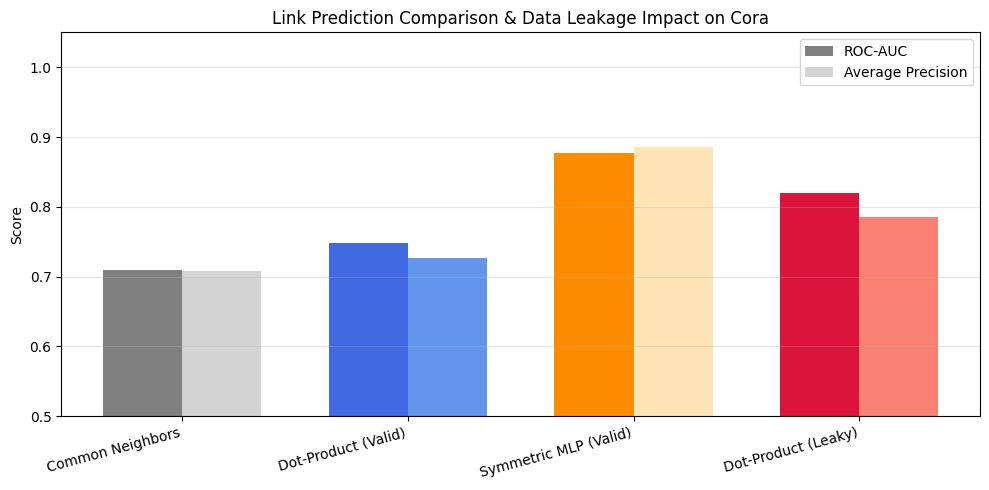

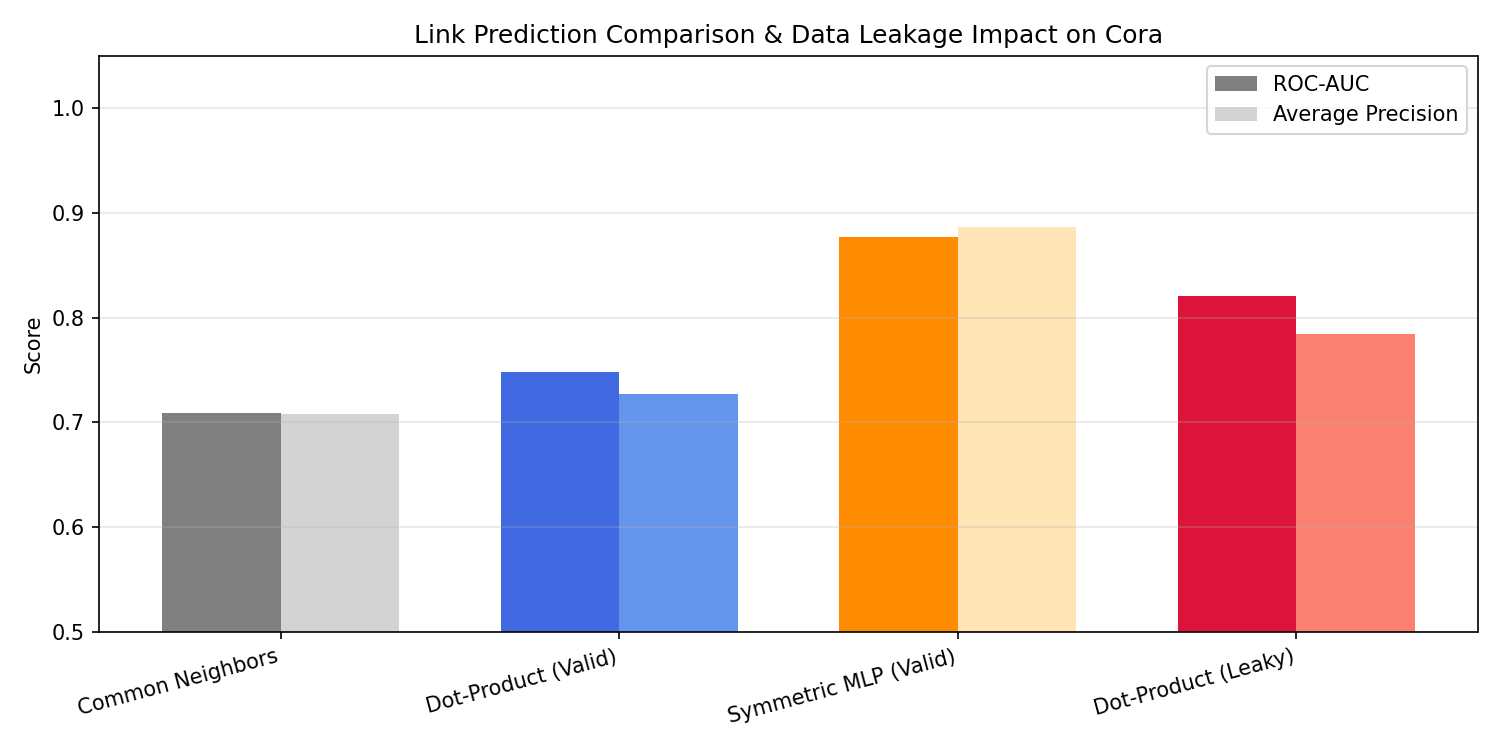


Saved comparison plot to: assignments/assignment_3_results.png

[SUCCESS] Assignment 3 execution completed successfully!


In [13]:
# CELL 13: VISUALIZATION & COLAB DISPLAY
# Generates a comparison bar chart of ROC-AUC and Average Precision across methods and leakage conditions.
# Saves assignment_3_results.png and displays directly inline in Google Colab.

methods = ["Common Neighbors", "Dot-Product (Valid)", "Symmetric MLP (Valid)", "Dot-Product (Leaky)"]
aucs = [cn_auc, dot_auc, mlp_auc, leaky_auc]
aps = [cn_ap, dot_ap, mlp_ap, leaky_ap]

fig, ax = plt.subplots(figsize=(10, 5))
x_pos = np.arange(len(methods))
width = 0.35

ax.bar(x_pos - width/2, aucs, width, label="ROC-AUC", color=["gray", "royalblue", "darkorange", "crimson"])
ax.bar(x_pos + width/2, aps, width, label="Average Precision", color=["lightgray", "cornflowerblue", "moccasin", "salmon"])

ax.set_ylabel("Score")
ax.set_title("Link Prediction Comparison & Data Leakage Impact on Cora")
ax.set_xticks(x_pos)
ax.set_xticklabels(methods, rotation=15, ha="right")
ax.set_ylim(0.5, 1.05)
ax.grid(axis="y", alpha=0.3)
ax.legend()

plt.tight_layout()
output_dir = "assignments"
os.makedirs(output_dir, exist_ok=True)
output_plot = os.path.join(output_dir, "assignment_3_results.png")
plt.savefig(output_plot, dpi=150)

try:
    plt.show()
except Exception:
    pass

try:
    from IPython.display import Image, display
    display(Image(output_plot))
except Exception:
    pass

plt.close()
print(f"\nSaved comparison plot to: {output_plot}")
print("\n[SUCCESS] Assignment 3 execution completed successfully!")
